In [79]:
import gc
from pathlib import Path
import platform
import random
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import time
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.tree import DecisionTreeRegressor

RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

In [80]:
candidatos_dados = [Path("dados/bruto"), Path("../dados/bruto")]
caminho_bruto = next((p for p in candidatos_dados if p.is_dir()), None)

if caminho_bruto is None:
    raise FileNotFoundError(
        "Não encontrei a pasta dados/bruto. Execute o notebook a partir da raiz "
        "do projeto ou da pasta notebooks/ e confira a estrutura de pastas."
    )

raiz_projeto = caminho_bruto.parent.parent.resolve()
arquivos_csv = sorted(caminho_bruto.glob("*.csv"))

if not arquivos_csv:
    raise FileNotFoundError(
        f"Nenhum arquivo CSV foi encontrado em: {caminho_bruto.resolve()}"
    )

dfs = []
colunas_padrao = None

for arquivo in arquivos_csv:
    df = pd.read_csv(arquivo, sep=';')

    df.columns = df.columns.astype(str).str.strip()

    print(f"\nArquivo: {arquivo.name} | {df.shape[0]:,} linhas, {df.shape[1]} colunas")
    display(df.head(2))

    colunas_atuais = list(df.columns)
    if colunas_padrao is None:
        colunas_padrao = colunas_atuais
    elif colunas_padrao != colunas_atuais:
        raise ValueError(
            f"O arquivo {arquivo.name} tem colunas diferentes dos demais. "
            "Confira os arquivos antes de concatená-los."
        )

    dfs.append(df)

df_unificado = pd.concat(dfs, ignore_index=True)
print(f"\nArquivos unidos com sucesso. Dimensões: {df_unificado.shape}")
display(df_unificado.head())


Arquivo: Preços semestrais - AUTOMOTIVOS_2024.01.csv | 477,154 linhas, 16 colunas


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA ADITIVADA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA



Arquivo: Preços semestrais - AUTOMOTIVOS_2024.02.csv | 421,382 linhas, 16 colunas


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,N,AC,RIO BRANCO,CODEPE COMBUSTIVEIS LTDA,08.220.930/0001-62,RODOVIA BR-364 (RIO BRANCO-CRUZEIRO DO SUL) - ...,2755,LOTE 01/02/03/04/05 E 33,PORTAL DA AMAZONIA,69915-630,GASOLINA,01/07/2024,"6,79",NaN,R$ / litro,VIBRA
1,N,AC,RIO BRANCO,CODEPE COMBUSTIVEIS LTDA,08.220.930/0001-62,RODOVIA BR-364 (RIO BRANCO-CRUZEIRO DO SUL) - ...,2755,LOTE 01/02/03/04/05 E 33,PORTAL DA AMAZONIA,69915-630,GASOLINA ADITIVADA,01/07/2024,"6,84",NaN,R$ / litro,VIBRA


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_25544\2370331544.py:22: DtypeWarning: Columns (0: Regiao - Sigla, 1: Estado - Sigla, 2: Municipio, 3: Revenda, 4: CNPJ da Revenda, 5: Nome da Rua, 6: Numero Rua, 7: Complemento, 8: Bairro, 9: Cep, 10: Produto, 11: Data da Coleta, 12: Valor de Venda, 14: Unidade de Medida, 15: Bandeira) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(arquivo, sep=';')



Arquivo: Preços semestrais - AUTOMOTIVOS_2025.01.csv | 429,523 linhas, 16 colunas


... (3 outputs left out)


Arquivo: Preços semestrais - AUTOMOTIVOS_2026.01.csv | 422,418 linhas, 16 colunas


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,GASOLINA,02/01/2026,"7,97",NaN,R$ / litro,IPIRANGA
1,N,AC,CRUZEIRO DO SUL,AMAZONIA COMERCIO DE DERIVADOS DE PETROLEO LTDA,01.492.748/0003-83,AVENIDA COPACABANA,440,NaN,COPACABANA,69980-000,DIESEL,02/01/2026,"8,15",NaN,R$ / litro,IPIRANGA



Arquivos unidos com sucesso. Dimensões: (2134685, 16)


,Regiao - Sigla,Estado - Sigla,Municipio,Revenda,CNPJ da Revenda,Nome da Rua,Numero Rua,Complemento,Bairro,Cep,Produto,Data da Coleta,Valor de Venda,Valor de Compra,Unidade de Medida,Bandeira
0,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA
1,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,GASOLINA ADITIVADA,01/01/2024,"5,68",NaN,R$ / litro,VIBRA
2,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,DIESEL S10,01/01/2024,"5,93",NaN,R$ / litro,VIBRA
3,NE,AL,ARAPIRACA,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...,02.817.655/0001-82,RODOVIA AL-220,1901,NaN,SANTA ESMERALDA,57312-025,ETANOL,01/01/2024,"3,99",NaN,R$ / litro,VIBRA
4,NE,AL,ARAPIRACA,AUTO POSTO SAO FRANCISCO LTDA,12.706.529/0001-04,RUA SAO FRANCISCO,274,NaN,CENTRO,57300-080,GASOLINA,01/01/2024,"5,48",NaN,R$ / litro,VIBRA


In [81]:
linhas, colunas = df_unificado.shape
linhas_duplicadas = df_unificado.duplicated().sum()

print("="*50)
print(" INSPEÇÃO GERAL DO DATASET")
print("="*50)
print(f"Dimensões globais : {linhas} linhas e {colunas} colunas")
print(f"Linhas duplicadas : {linhas_duplicadas} ocorrencias exatas")
print("="*50 + "\n")

inspecao = pd.DataFrame({
    'Tipo': df_unificado.dtypes,
    'Ausências (Qtd)': df_unificado.isnull().sum(),
    'Ausências (%)': (df_unificado.isnull().sum() / linhas) * 100,
    'Chaves/Únicos': df_unificado.nunique()
})

amostras = []
for col in df_unificado.columns:
    valores = df_unificado[col].dropna().unique()
    amostra_str = ", ".join(map(str, valores[:3]))
    if len(valores) > 3:
        amostra_str += ", ..."
    amostras.append(amostra_str)

inspecao['Categorias (Amostras)'] = amostras

inspecao['Ausências (%)'] = inspecao['Ausências (%)'].round(2).astype(str) + '%'

inspecao = inspecao.sort_values(by='Ausências (Qtd)', ascending=False)

display(inspecao)

 INSPEÇÃO GERAL DO DATASET
Dimensões globais : 2134685 linhas e 16 colunas
Linhas duplicadas : 9129 ocorrencias exatas



,Tipo,Ausências (Qtd),Ausências (%),Chaves/Únicos,Categorias (Amostras)
Valor de Compra,float64,2134685,100.0%,0,
Complemento,str,1649676,77.28%,2362,"KM 70, LOTE 12 QUADRAB, L..."
Bairro,str,12807,0.6%,5511,"SANTA ESMERALDA, CENTRO, CANAFISTULA, ..."
Numero Rua,str,9367,0.44%,4158,"1901, 274, 678, ..."
Revenda,str,9114,0.43%,11558,COMERCIAL DE COMBUSTIVEIS E LUBRIFICANTES VITA...
Municipio,str,9114,0.43%,461,"ARAPIRACA, RIO LARGO, VERA CRUZ, ..."
Regiao - Sigla,str,9114,0.43%,5,"NE, SE, S, ..."
Estado - Sigla,str,9114,0.43%,27,"AL, BA, MA, ..."
CNPJ da Revenda,object,9114,0.43%,20767,"02.817.655/0001-82, 12.706.529/0001-04, 01...."
Nome da Rua,str,9114,0.43%,8189,"RODOVIA AL-220, RUA SAO FRANCISCO, RODOVIA AL-..."


In [82]:
import re
import unicodedata

df_transformado = df_unificado.copy()

df_transformado.columns = [
    re.sub(
        r"_+",
        "_",
        unicodedata.normalize("NFKD", str(c))
        .encode("ascii", "ignore")
        .decode("utf-8")
        .strip()
        .lower()
        .replace("-", "_")
        .replace(" ", "_")
    ).strip("_")
    for c in df_transformado.columns
]

linhas_brutas = len(df_transformado)
df_transformado = df_transformado.drop_duplicates().copy()
duplicadas_removidas = linhas_brutas - len(df_transformado)

df_transformado["data_da_coleta"] = pd.to_datetime(
    df_transformado["data_da_coleta"].astype("string").str.strip(),
    format="%d/%m/%Y",
    errors="coerce"
).dt.normalize()

df_transformado["valor_de_venda"] = pd.to_numeric(
    df_transformado["valor_de_venda"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False),
    errors="coerce"
)

for col_txt in ["regiao_sigla", "estado_sigla", "produto", "bandeira", "unidade_de_medida"]:
    if col_txt in df_transformado.columns:
        df_transformado[col_txt] = (
            df_transformado[col_txt].astype("string").str.strip().str.lower()
        )

mask_validos = (
    df_transformado["data_da_coleta"].notna()
    & df_transformado["valor_de_venda"].notna()
    & (df_transformado["valor_de_venda"] > 0).fillna(False)
    & df_transformado["unidade_de_medida"].eq("r$ / litro").fillna(False)
)
linhas_invalidas = (~mask_validos).sum()
df_transformado = df_transformado.loc[mask_validos].copy()

DATA_LIMITE = pd.Timestamp("2026-11-25")
mask_futuras = df_transformado["data_da_coleta"] > DATA_LIMITE
registros_futuros = mask_futuras.sum()
df_transformado = df_transformado.loc[~mask_futuras].copy()

df_transformado["ano_coleta"] = df_transformado["data_da_coleta"].dt.year
df_transformado["mes_coleta"] = df_transformado["data_da_coleta"].dt.month

bandeira = df_transformado["bandeira"].fillna("não consta")
df_transformado["tipo_bandeira"] = np.select(
    [bandeira.eq("branca"), bandeira.eq("não consta")],
    ["independente", "não consta"],
    default="rede_franqueada"
)

CAMINHO_DADOS = (raiz_projeto / "dados" / "processado" / "base_anp_transformada.csv").resolve()
CAMINHO_DADOS.parent.mkdir(parents=True, exist_ok=True)
df_transformado.to_csv(CAMINHO_DADOS, index=False, sep=",", date_format="%Y-%m-%d")

print(f"Duplicatas exatas removidas: {duplicadas_removidas:,}")
print(f"Registros removidos (inválidos ou GNV em m³): {linhas_invalidas:,}")
print(f"Registros removidos por data futura: {registros_futuros:,}")
print(f"Total de registros válidos: {len(df_transformado):,}")
print(f"Período: {df_transformado['data_da_coleta'].min().date()} até {df_transformado['data_da_coleta'].max().date()}")

Duplicatas exatas removidas: 9,129
Registros removidos (inválidos ou GNV em m³): 45,619
Registros removidos por data futura: 0
Total de registros válidos: 2,079,937
Período: 2024-01-01 até 2026-06-30


In [83]:
COL_DATA = "data_da_coleta"
COL_ALVO = "valor_de_venda"
COL_ESTADO = "estado_sigla"
COL_REGIAO = "regiao_sigla"
COL_PRODUTO = "produto"
COL_BANDEIRA = "bandeira"

df = pd.read_csv(CAMINHO_DADOS, sep=",", low_memory=False)
df[COL_DATA] = pd.to_datetime(df[COL_DATA], format="%Y-%m-%d", errors="coerce")
df[COL_ALVO] = pd.to_numeric(df[COL_ALVO], errors="coerce")

df = df.sort_values(COL_DATA).reset_index(drop=True)

df["ano"] = df[COL_DATA].dt.year.astype("int16")
df["mes"] = df[COL_DATA].dt.month.astype("int8")
df["trimestre"] = df[COL_DATA].dt.quarter.astype("int8")
df["dia_semana"] = df[COL_DATA].dt.dayofweek.astype("int8")

datas_unicas = np.sort(df[COL_DATA].unique())
n_datas = len(datas_unicas)

corte_treino = datas_unicas[int(n_datas * 0.70)]
corte_val = datas_unicas[int(n_datas * 0.85)]

df_treino = df[df[COL_DATA] <= corte_treino].copy()
df_val = df[(df[COL_DATA] > corte_treino) & (df[COL_DATA] <= corte_val)].copy()
df_teste = df[df[COL_DATA] > corte_val].copy()

print(f"Total de registros válidos: {len(df):,} | Datas únicas: {n_datas}")
print(f"Treino:    {len(df_treino):,} ({len(df_treino)/len(df):.1%}) | Até {df_treino[COL_DATA].max().date()}")
print(f"Validação: {len(df_val):,} ({len(df_val)/len(df):.1%}) | Até {df_val[COL_DATA].max().date()}")
print(f"Teste:     {len(df_teste):,} ({len(df_teste)/len(df):.1%}) | Até {df_teste[COL_DATA].max().date()}")

del df
gc.collect()

Total de registros válidos: 2,079,937 | Datas únicas: 680
Treino:    1,473,257 (70.8%) | Até 2025-10-02
Validação: 296,997 (14.3%) | Até 2026-02-17
Teste:     309,683 (14.9%) | Até 2026-06-30


4102

In [84]:
candidatas_cat = [COL_REGIAO, COL_ESTADO, COL_PRODUTO, COL_BANDEIRA]
candidatas_num = ["ano", "mes", "trimestre", "dia_semana"]

features_cat = [c for c in candidatas_cat if c in df_treino.columns]
features_num = [c for c in candidatas_num if c in df_treino.columns]
features_modelo = features_cat + features_num

X_treino = df_treino[features_modelo].copy()
y_treino = df_treino[COL_ALVO].astype("float32").values

X_val = df_val[features_modelo].copy()
y_val = df_val[COL_ALVO].astype("float32").values

X_teste = df_teste[features_modelo].copy()
y_teste = df_teste[COL_ALVO].astype("float32").values

pipe_cat = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=0.005, sparse_output=False, dtype=np.float32))
])

pipe_num = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

preprocessador = ColumnTransformer(
    transformers=[
        ("cat", pipe_cat, features_cat),
        ("num", pipe_num, features_num)
    ],
    remainder="drop"
)

print(f"Features categóricas: {features_cat}")
print(f"Features numéricas: {features_num}")
print(f"Registros de treino: {len(X_treino):,}")
print(f"Registros de validação: {len(X_val):,}")
print(f"Registros de teste: {len(X_teste):,}")

Features categóricas: ['regiao_sigla', 'estado_sigla', 'produto', 'bandeira']
Features numéricas: ['ano', 'mes', 'trimestre', 'dia_semana']
Registros de treino: 1,473,257
Registros de validação: 296,997
Registros de teste: 309,683


In [85]:
def avaliar_regressao(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    return mae, rmse

mediana_global = float(np.median(y_treino))
pred_trivial_val = np.full(len(y_val), mediana_global, dtype="float32")
pred_trivial_teste = np.full(len(y_teste), mediana_global, dtype="float32")

mapa_estado_prod = df_treino.groupby([COL_ESTADO, COL_PRODUTO])[COL_ALVO].median()
mapa_prod = df_treino.groupby(COL_PRODUTO)[COL_ALVO].median()

def prever_baseline_operacional(df_alvo):
    idx = pd.MultiIndex.from_frame(df_alvo[[COL_ESTADO, COL_PRODUTO]])
    preds = mapa_estado_prod.reindex(idx).to_numpy(dtype="float32", copy=True)
    nulos = np.isnan(preds)
    if nulos.any():
        preds[nulos] = df_alvo.loc[nulos, COL_PRODUTO].map(mapa_prod).fillna(mediana_global).to_numpy(dtype="float32")
    return preds

pred_op_val = prever_baseline_operacional(df_val)
pred_op_teste = prever_baseline_operacional(df_teste)

resultados_baselines = pd.DataFrame([
    {
        "Modelo": "Baseline Trivial (Mediana Global)",
        "MAE Validação": avaliar_regressao(y_val, pred_trivial_val)[0],
        "RMSE Validação": avaliar_regressao(y_val, pred_trivial_val)[1],
        "MAE Teste": avaliar_regressao(y_teste, pred_trivial_teste)[0],
        "RMSE Teste": avaliar_regressao(y_teste, pred_trivial_teste)[1],
    },
    {
        "Modelo": "Baseline Operacional (Mediana Estado + Produto)",
        "MAE Validação": avaliar_regressao(y_val, pred_op_val)[0],
        "RMSE Validação": avaliar_regressao(y_val, pred_op_val)[1],
        "MAE Teste": avaliar_regressao(y_teste, pred_op_teste)[0],
        "RMSE Teste": avaliar_regressao(y_teste, pred_op_teste)[1],
    }
])

print(resultados_baselines.to_string(index=False))

                                         Modelo  MAE Validação  RMSE Validação  MAE Teste  RMSE Teste
              Baseline Trivial (Mediana Global)       0.599407        0.817452   0.991715    1.132781
Baseline Operacional (Mediana Estado + Produto)       0.293882        0.398871   0.721772    0.866498


In [86]:
datas_treino_cv = pd.to_datetime(df_treino[COL_DATA]).reset_index(drop=True)
datas_unicas_cv = np.sort(datas_treino_cv.unique())
tscv = TimeSeriesSplit(n_splits=3)
cv_divisoes = []

for idx_treino_datas, idx_validacao_datas in tscv.split(datas_unicas_cv):
    datas_fold_treino = datas_unicas_cv[idx_treino_datas]
    datas_fold_validacao = datas_unicas_cv[idx_validacao_datas]
    idx_treino = np.flatnonzero(datas_treino_cv.isin(datas_fold_treino).to_numpy())
    idx_validacao = np.flatnonzero(datas_treino_cv.isin(datas_fold_validacao).to_numpy())
    cv_divisoes.append((idx_treino, idx_validacao))

registros_tuning = {}

def executar_tuning(nome, estimador, grade_params):
    inicio = time.perf_counter()
    pipeline = Pipeline([
        ("prep", clone(preprocessador)),
        ("modelo", estimador)
    ])
    busca = GridSearchCV(
        estimator=pipeline,
        param_grid=grade_params,
        cv=cv_divisoes,
        scoring="neg_mean_absolute_error",
        n_jobs=1,
        refit=True
    )
    busca.fit(X_treino, y_treino)
    tempo_treino = time.perf_counter() - inicio

    melhor_modelo = busca.best_estimator_
    pred_val = melhor_modelo.predict(X_val)
    mae_val, rmse_val = avaliar_regressao(y_val, pred_val)
    mae_cv = -float(busca.best_score_)

    params_limpos = {k.replace("modelo__", ""): v for k, v in busca.best_params_.items()}
    registros_tuning[nome] = {
        "modelo": melhor_modelo,
        "melhores_params": params_limpos,
        "mae_cv": mae_cv,
        "mae_val": mae_val,
        "rmse_val": rmse_val,
        "tempo_s": tempo_treino
    }
    gc.collect()
    print(f"{nome} | Tempo: {tempo_treino:.1f}s | MAE CV: {mae_cv:.6f} | MAE Val: {mae_val:.6f} | RMSE Val: {rmse_val:.6f}")
    print(f"Melhores hiperparâmetros: {params_limpos}")

In [87]:
grade_ridge = {
    "modelo__alpha": [0.1, 1.0, 10.0, 100.0]
}

executar_tuning(
    nome="Regressão Linear Regularizada (Ridge)",
    estimador=Ridge(random_state=RANDOM_STATE),
    grade_params=grade_ridge
)

Regressão Linear Regularizada (Ridge) | Tempo: 73.9s | MAE CV: 0.381898 | MAE Val: 0.324716 | RMSE Val: 0.408742
Melhores hiperparâmetros: {'alpha': 100.0}


In [88]:
grade_arvore = {
    "modelo__max_depth": [6, 10, 14],
    "modelo__min_samples_leaf": [50, 200]
}

executar_tuning(
    nome="Árvore de Decisão (DecisionTree)",
    estimador=DecisionTreeRegressor(random_state=RANDOM_STATE),
    grade_params=grade_arvore
)

Árvore de Decisão (DecisionTree) | Tempo: 175.0s | MAE CV: 0.340337 | MAE Val: 0.248346 | RMSE Val: 0.334435
Melhores hiperparâmetros: {'max_depth': 14, 'min_samples_leaf': 50}


In [89]:
grade_hgb = {
    "modelo__max_iter": [100, 200],
    "modelo__learning_rate": [0.05, 0.1],
    "modelo__max_leaf_nodes": [31, 63]
}

executar_tuning(
    nome="Ensemble (HistGradientBoosting)",
    estimador=HistGradientBoostingRegressor(random_state=RANDOM_STATE),
    grade_params=grade_hgb
)

resumo_val = pd.DataFrame([
    {
        "Modelo": nome,
        "MAE CV (Treino)": info["mae_cv"],
        "MAE Validação": info["mae_val"],
        "RMSE Validação": info["rmse_val"],
        "Tempo (s)": round(info["tempo_s"], 2),
        "Hiperparâmetros": str(info["melhores_params"])
    }
    for nome, info in registros_tuning.items()
])

print("\nResumo dos candidatos na validação:")
print(resumo_val.to_string(index=False))

Ensemble (HistGradientBoosting) | Tempo: 571.9s | MAE CV: 0.337954 | MAE Val: 0.246442 | RMSE Val: 0.330844
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 63}

Resumo dos candidatos na validação:
                               Modelo  MAE CV (Treino)  MAE Validação  RMSE Validação  Tempo (s)                                               Hiperparâmetros
Regressão Linear Regularizada (Ridge)         0.381898       0.324716        0.408742      73.88                                              {'alpha': 100.0}
     Árvore de Decisão (DecisionTree)         0.340337       0.248346        0.334435     175.02                     {'max_depth': 14, 'min_samples_leaf': 50}
      Ensemble (HistGradientBoosting)         0.337954       0.246442        0.330844     571.93 {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 63}


In [90]:
modelos_esperados = [
    "Regressão Linear Regularizada (Ridge)",
    "Árvore de Decisão (DecisionTree)",
    "Ensemble (HistGradientBoosting)"
]

modelos_ausentes = [nome for nome in modelos_esperados if nome not in registros_tuning]
if modelos_ausentes:
    raise RuntimeError(f"Modelos ainda não treinados: {modelos_ausentes}. Execute novamente as células de treinamento.")

predicoes_teste = {}
linhas_comparacao = []

for nome in modelos_esperados:
    info = registros_tuning[nome]
    predicao = info["modelo"].predict(X_teste)
    predicoes_teste[nome] = predicao
    mae_teste, rmse_teste = avaliar_regressao(y_teste, predicao)
    linhas_comparacao.append({
        "Modelo": nome,
        "MAE CV (Treino)": info["mae_cv"],
        "MAE Validação": info["mae_val"],
        "RMSE Validação": info["rmse_val"],
        "MAE Teste": mae_teste,
        "RMSE Teste": rmse_teste,
        "Tempo (s)": round(info["tempo_s"], 2),
        "Hiperparâmetros": str(info["melhores_params"])
    })

linhas_baselines = []
for _, linha in resultados_baselines.iterrows():
    linhas_baselines.append({
        "Modelo": linha["Modelo"],
        "MAE CV (Treino)": np.nan,
        "MAE Validação": linha["MAE Validação"],
        "RMSE Validação": linha["RMSE Validação"],
        "MAE Teste": linha["MAE Teste"],
        "RMSE Teste": linha["RMSE Teste"],
        "Tempo (s)": 0.0,
        "Hiperparâmetros": "-"
    })

quadro_comparativo = pd.DataFrame(
    linhas_baselines + linhas_comparacao
)

melhor_nome = min(
    modelos_esperados,
    key=lambda nome: registros_tuning[nome]["mae_val"]
)
melhor_modelo = registros_tuning[melhor_nome]["modelo"]
pred_melhor_teste = predicoes_teste[melhor_nome]

print("Quadro comparativo completo:")
print(quadro_comparativo.to_string(index=False))
print(f"\nModelo selecionado pela validação: {melhor_nome}")

Quadro comparativo completo:
                                         Modelo  MAE CV (Treino)  MAE Validação  RMSE Validação  MAE Teste  RMSE Teste  Tempo (s)                                               Hiperparâmetros
              Baseline Trivial (Mediana Global)              NaN       0.599407        0.817452   0.991715    1.132781       0.00                                                             -
Baseline Operacional (Mediana Estado + Produto)              NaN       0.293882        0.398871   0.721772    0.866498       0.00                                                             -
          Regressão Linear Regularizada (Ridge)         0.381898       0.324716        0.408742   0.413895    0.549446      73.88                                              {'alpha': 100.0}
               Árvore de Decisão (DecisionTree)         0.340337       0.248346        0.334435   0.550964    0.700822     175.02                     {'max_depth': 14, 'min_samples_leaf': 50}
           

In [91]:
mae_op_teste, rmse_op_teste = avaliar_regressao(
    y_teste, pred_op_teste
)

mae_triv_teste, rmse_triv_teste = avaliar_regressao(
    y_teste, pred_trivial_teste
)

mae_venc_teste, rmse_venc_teste = avaliar_regressao(
    y_teste, pred_melhor_teste
)

reducao_erro_litro = mae_op_teste - mae_venc_teste
reducao_erro_percentual = (
    reducao_erro_litro / mae_op_teste * 100
    if mae_op_teste > 0 else np.nan
)

reducao_erro_trivial = mae_triv_teste - mae_venc_teste
reducao_percentual_trivial = (
    reducao_erro_trivial / mae_triv_teste * 100
    if mae_triv_teste > 0 else np.nan
)

tabela_ganho = pd.DataFrame([
    {"Indicador": "MAE Baseline Trivial (R$/L)", "Valor": mae_triv_teste},
    {"Indicador": "MAE Baseline Operacional (R$/L)", "Valor": mae_op_teste},
    {"Indicador": f"MAE {melhor_nome} (R$/L)", "Valor": mae_venc_teste},
    {"Indicador": "Diferença de MAE vs. Baseline Operacional (R$/L)", "Valor": reducao_erro_litro},
    {"Indicador": "Redução percentual do MAE vs. Baseline Operacional (%)", "Valor": reducao_erro_percentual},
    {"Indicador": "Diferença de MAE vs. Baseline Trivial (R$/L)", "Valor": reducao_erro_trivial},
    {"Indicador": "Redução percentual do MAE vs. Baseline Trivial (%)", "Valor": reducao_percentual_trivial}
])

tabela_ganho["Valor"] = tabela_ganho["Valor"].round(6)
print(tabela_ganho.to_string(index=False))

                                             Indicador     Valor
                           MAE Baseline Trivial (R$/L)  0.991715
                       MAE Baseline Operacional (R$/L)  0.721772
            MAE Ensemble (HistGradientBoosting) (R$/L)  0.549363
      Diferença de MAE vs. Baseline Operacional (R$/L)  0.172409
Redução percentual do MAE vs. Baseline Operacional (%) 23.886960
          Diferença de MAE vs. Baseline Trivial (R$/L)  0.442353
    Redução percentual do MAE vs. Baseline Trivial (%) 44.604804


In [92]:
df_operacao = pd.DataFrame({
    "estado": df_teste[COL_ESTADO].astype("string").str.strip().str.lower().fillna("não informado").values,
    "regiao": df_teste[COL_REGIAO].astype("string").str.strip().str.lower().fillna("não informado").values,
    "produto": df_teste[COL_PRODUTO].astype("string").str.strip().str.lower().fillna("não informado").values,
    "preco_real": y_teste,
    "preco_estimado": pred_melhor_teste
})

df_operacao["erro"] = df_operacao["preco_real"] - df_operacao["preco_estimado"]
df_operacao["erro_abs"] = df_operacao["erro"].abs()

resumo_nacional = pd.DataFrame([{
    "abrangencia": "Brasil",
    "registros": len(df_operacao),
    "preco_real_medio": df_operacao["preco_real"].mean(),
    "preco_estimado_medio": df_operacao["preco_estimado"].mean(),
    "mae": df_operacao["erro_abs"].mean(),
    "rmse": np.sqrt(np.mean(df_operacao["erro"] ** 2)),
    "vies_medio": df_operacao["erro"].mean()
}])

resumo_estadual = (
    df_operacao
    .groupby("estado", dropna=False)
    .agg(
        registros=("erro_abs", "count"),
        preco_real_medio=("preco_real", "mean"),
        preco_estimado_medio=("preco_estimado", "mean"),
        mae=("erro_abs", "mean"),
        rmse=("erro", lambda s: np.sqrt(np.mean(s ** 2))),
        vies_medio=("erro", "mean")
    )
    .reset_index()
    .sort_values("estado")
)

print("ANÁLISE NACIONAL")
print(resumo_nacional.to_string(index=False))
print("\nANÁLISE POR ESTADO")
print(resumo_estadual.to_string(index=False))

ANÁLISE NACIONAL
abrangencia  registros  preco_real_medio  preco_estimado_medio      mae     rmse  vies_medio
     Brasil     309683           6.37217              5.912982 0.549363 0.698163    0.459189

ANÁLISE POR ESTADO
estado  registros  preco_real_medio  preco_estimado_medio      mae     rmse  vies_medio
    ac        960          7.353427              7.031057 0.465414 0.588898    0.322371
    al       3449          6.507199              6.046882 0.510701 0.671505    0.460317
    am       3675          7.029850              6.783509 0.472527 0.674486    0.246341
    ap        410          6.629464              7.083996 0.574520 0.668461   -0.454533
    ba      17311          6.907022              6.038171 0.930529 1.110791    0.868851
    ce       9609          6.588475              6.173775 0.504478 0.611274    0.414700
    df       2750          6.341793              6.201992 0.355592 0.498534    0.139800
    es       5515          6.337955              5.978436 0.426681 0.5125

In [93]:
df_erros = pd.DataFrame({
    "data": pd.to_datetime(df_teste[COL_DATA]).values,
    "regiao": df_teste[COL_REGIAO].astype("string").str.strip().str.lower().fillna("não informado").values,
    "estado": df_teste[COL_ESTADO].astype("string").str.strip().str.lower().fillna("não informado").values,
    "produto": df_teste[COL_PRODUTO].astype("string").str.strip().str.lower().fillna("não informado").values,
    "bandeira": df_teste[COL_BANDEIRA].astype("string").str.strip().str.lower().fillna("não informado").values,
    "ano": df_teste["ano"].values,
    "mes": df_teste["mes"].values,
    "y_real": y_teste,
    "y_pred": pred_melhor_teste,
    "erro": y_teste - pred_melhor_teste,
    "erro_abs": np.abs(y_teste - pred_melhor_teste)
})

df_erros["tipo_erro"] = np.select(
    [df_erros["erro"] > 0, df_erros["erro"] < 0],
    ["Subestimação", "Superestimação"],
    default="Erro zero"
)

df_erros["faixa_preco"] = pd.qcut(
    df_erros["y_real"],
    q=4,
    duplicates="drop"
)

resumo_faixas = (
    df_erros.groupby("faixa_preco", observed=False)
    .agg(
        registros=("y_real", "count"),
        preco_medio=("y_real", "mean"),
        mae=("erro_abs", "mean"),
        rmse=("erro", lambda s: np.sqrt(np.mean(s ** 2))),
        vies_medio=("erro", "mean"),
        p90_erro_abs=("erro_abs", lambda s: np.percentile(s, 90))
    )
    .reset_index()
)

resumo_assimetria = (
    df_erros.groupby("tipo_erro", dropna=False)
    .agg(
        registros=("erro", "count"),
        proporcao_pct=("erro", lambda s: round(len(s) / len(df_erros) * 100, 2)),
        mae=("erro_abs", "mean"),
        vies_medio=("erro", "mean")
    )
    .reset_index()
)

perfis_problematicos = (
    df_erros.groupby(["estado", "produto", "bandeira"], dropna=False)
    .agg(
        registros=("erro_abs", "count"),
        preco_real_medio=("y_real", "mean"),
        preco_prev_medio=("y_pred", "mean"),
        mae=("erro_abs", "mean"),
        vies_medio=("erro", "mean")
    )
    .reset_index()
    .query("registros >= 50")
    .sort_values("mae", ascending=False)
    .head(10)
)

print("Erro por faixa de preço:")
print(resumo_faixas.to_string(index=False))
print("\nAssimetria dos erros:")
print(resumo_assimetria.to_string(index=False))
print("\nPerfis com maiores erros:")
print(perfis_problematicos.to_string(index=False))

Erro por faixa de preço:
               faixa_preco  registros  preco_medio      mae     rmse  vies_medio  p90_erro_abs
(2.8890000000000002, 5.99]      81976     4.867179 0.352490 0.429485    0.120092      0.682362
              (5.99, 6.65]      73566     6.408212 0.243564 0.309795    0.133440      0.498373
              (6.65, 6.99]      79093     6.852789 0.536318 0.592835    0.528693      0.881643
              (6.99, 9.99]      75048     7.474242 1.077918 1.159919    1.075655      1.624789

Assimetria dos erros:
     tipo_erro  registros  proporcao_pct     mae  vies_medio
  Subestimação     254777          82.27 0.61295     0.61295
Superestimação      54906          17.73 0.25430    -0.25430

Perfis com maiores erros:
estado    produto   bandeira  registros  preco_real_medio  preco_prev_medio      mae  vies_medio
    ba diesel s10 petrobahia         64          7.580156          6.164748 1.505001    1.415408
    ba     diesel   ipiranga        271          7.678634          6.2763

In [94]:
mae_global_teste = float(df_erros["erro_abs"].mean())

def avaliar_equidade_grupo(coluna, min_registros=1):
    tabela = (
        df_erros.groupby(coluna, dropna=False)
        .agg(
            registros=("erro_abs", "count"),
            proporcao_pct=("erro_abs", lambda s: round(len(s) / len(df_erros) * 100, 2)),
            mae=("erro_abs", "mean"),
            rmse=("erro", lambda s: np.sqrt(np.mean(s ** 2))),
            vies_medio=("erro", "mean")
        )
        .reset_index()
        .query("registros >= @min_registros")
        .sort_values("mae", ascending=False)
    )
    tabela["razao_disparidade_mae"] = (tabela["mae"] / mae_global_teste).round(3)
    return tabela

eq_produto = avaliar_equidade_grupo("produto", min_registros=1)
eq_regiao = avaliar_equidade_grupo("regiao", min_registros=1)
eq_estado = avaliar_equidade_grupo("estado", min_registros=1)
eq_bandeira = (
    avaliar_equidade_grupo("bandeira", min_registros=1)
    .sort_values(["registros", "mae"], ascending=[False, False])
    .head(10)
)

nome_ridge = "Regressão Linear Regularizada (Ridge)"
df_erros["erro_ridge"] = y_teste - predicoes_teste[nome_ridge]
df_erros["erro_abs_ridge"] = df_erros["erro_ridge"].abs()

df_erros["ano_mes"] = pd.to_datetime(df_erros["data"]).dt.to_period("M").astype(str)

comp_temporal = (
    df_erros.groupby("ano")
    .agg(
        registros=("erro_abs", "count"),
        mae_modelo_vencedor=("erro_abs", "mean"),
        mae_ridge=("erro_abs_ridge", "mean"),
        vies_modelo_vencedor=("erro", "mean")
    )
    .reset_index()
)

comp_temporal_mes = (
    df_erros.groupby("ano_mes")
    .agg(
        registros=("erro_abs", "count"),
        mae_modelo_vencedor=("erro_abs", "mean"),
        rmse_modelo_vencedor=("erro", lambda s: np.sqrt(np.mean(s ** 2))),
        vies_modelo_vencedor=("erro", "mean"),
        mae_ridge=("erro_abs_ridge", "mean"),
        rmse_ridge=("erro_ridge", lambda s: np.sqrt(np.mean(s ** 2)))
    )
    .reset_index()
    .sort_values("ano_mes")
)

print("Equidade nacional por produto:")
print(eq_produto.to_string(index=False))
print("\nEquidade nacional por região:")
print(eq_regiao.to_string(index=False))
print("\nEquidade nacional por estado:")
print(eq_estado.sort_values("estado").to_string(index=False))
print("\nDez bandeiras com maior volume:")
print(eq_bandeira.to_string(index=False))
print("\nComparação temporal anual:")
print(comp_temporal.to_string(index=False))
print("\nComparação temporal mensal:")
print(comp_temporal_mes.to_string(index=False))

Equidade nacional por produto:
           produto  registros  proporcao_pct      mae     rmse  vies_medio  razao_disparidade_mae
        diesel s10      57787          18.66 0.945916 1.057023    0.853384                  1.722
            diesel      34292          11.07 0.849506 0.973464    0.757538                  1.546
gasolina aditivada      64301          20.76 0.420616 0.528563    0.353541                  0.766
          gasolina      82983          26.80 0.419002 0.522651    0.350527                  0.763
            etanol      70320          22.71 0.348681 0.434170    0.214593                  0.635

Equidade nacional por região:
regiao  registros  proporcao_pct      mae     rmse  vies_medio  razao_disparidade_mae
    ne      63351          20.46 0.703110 0.860121    0.634845                  1.280
     n      18661           6.03 0.573231 0.708059    0.443418                  1.043
    se     149288          48.21 0.523707 0.664974    0.436383                  0.953
    co

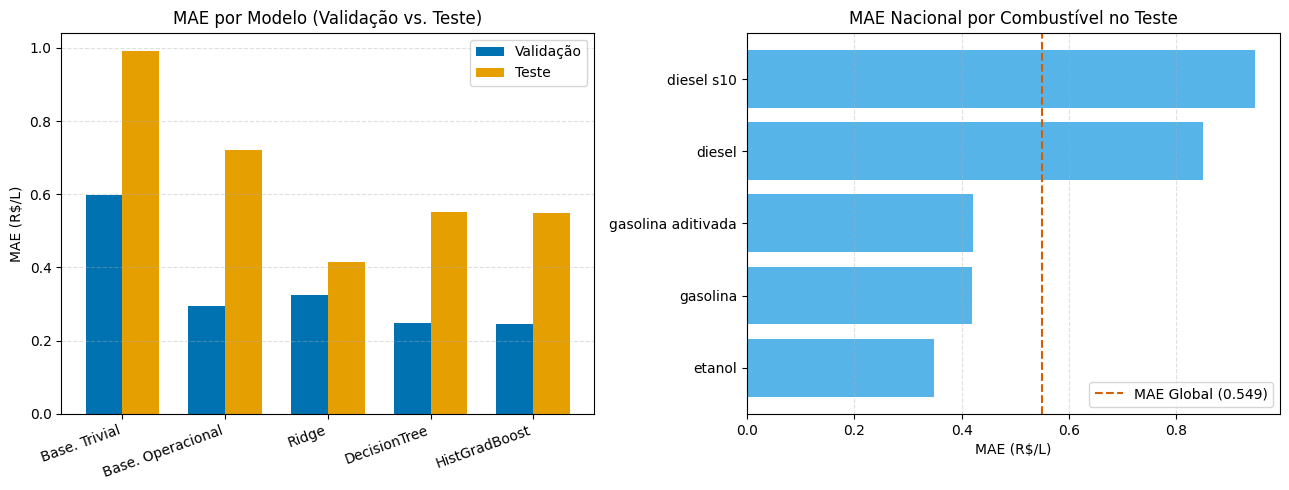

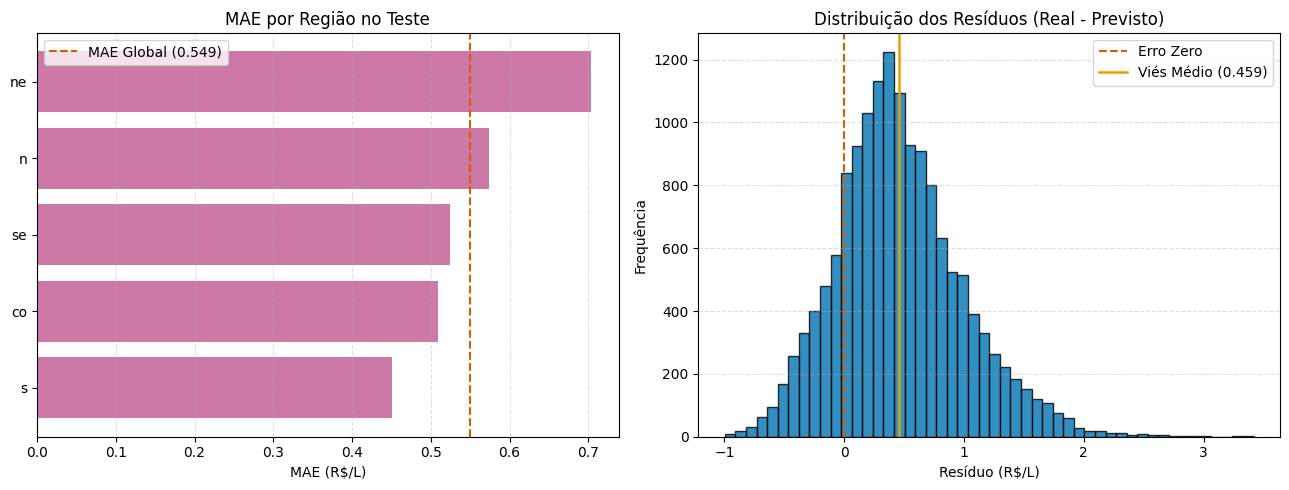

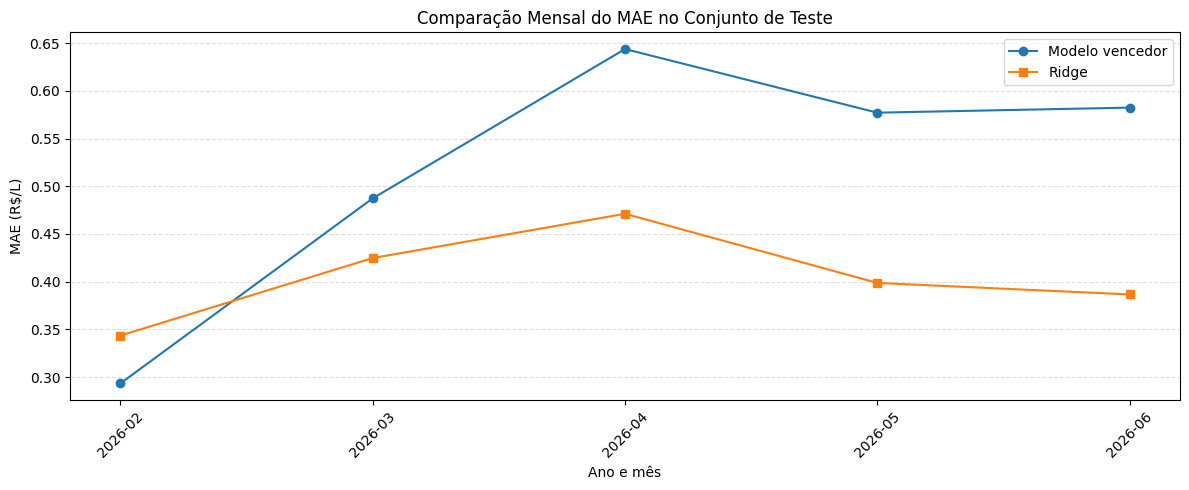

Gráficos salvos em: ..\docs\graficos\fig1_comparacao_e_produtos.png, ..\docs\graficos\fig2_equidade_e_residuos.png e ..\docs\graficos\fig3_comparacao_mensal_erros.png


In [95]:
import matplotlib.pyplot as plt

pasta_docs = Path("../docs/graficos") if Path("../docs").exists() else Path("docs/graficos")
pasta_docs.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

nomes_curtos = ["Base. Trivial", "Base. Operacional", "Ridge", "DecisionTree", "HistGradBoost"]
mae_val_plot = quadro_comparativo["MAE Validação"].values
mae_teste_plot = quadro_comparativo["MAE Teste"].values
x = np.arange(len(nomes_curtos))
largura = 0.36

axes[0].bar(x - largura / 2, mae_val_plot, largura, label="Validação", color="#0072B2")
axes[0].bar(x + largura / 2, mae_teste_plot, largura, label="Teste", color="#E69F00")
axes[0].set_title("MAE por Modelo (Validação vs. Teste)")
axes[0].set_ylabel("MAE (R$/L)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(nomes_curtos, rotation=20, ha="right")
axes[0].legend()
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

eq_prod_ord = eq_produto.sort_values("mae", ascending=True)
axes[1].barh(eq_prod_ord["produto"], eq_prod_ord["mae"], color="#56B4E9")
axes[1].axvline(mae_global_teste, color="#D55E00", linestyle="--", linewidth=1.5, label=f"MAE Global ({mae_global_teste:.3f})")
axes[1].set_title("MAE Nacional por Combustível no Teste")
axes[1].set_xlabel("MAE (R$/L)")
axes[1].legend()
axes[1].grid(axis="x", linestyle="--", alpha=0.4)

plt.tight_layout()
caminho_fig1 = pasta_docs / "fig1_comparacao_e_produtos.png"
plt.savefig(caminho_fig1, dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

eq_reg_ord = eq_regiao.sort_values("mae", ascending=True)
axes[0].barh(eq_reg_ord["regiao"], eq_reg_ord["mae"], color="#CC79A7")
axes[0].axvline(mae_global_teste, color="#D55E00", linestyle="--", linewidth=1.5, label=f"MAE Global ({mae_global_teste:.3f})")
axes[0].set_title("MAE por Região no Teste")
axes[0].set_xlabel("MAE (R$/L)")
axes[0].legend()
axes[0].grid(axis="x", linestyle="--", alpha=0.4)

amostra_idx = np.random.choice(len(df_erros), size=min(15000, len(df_erros)), replace=False)
axes[1].hist(df_erros["erro"].iloc[amostra_idx], bins=50, color="#0072B2", edgecolor="black", alpha=0.8)
axes[1].axvline(0, color="#D55E00", linestyle="--", linewidth=1.5, label="Erro Zero")
axes[1].axvline(df_erros["erro"].mean(), color="#E69F00", linestyle="-", linewidth=1.8, label=f"Viés Médio ({df_erros['erro'].mean():.3f})")
axes[1].set_title("Distribuição dos Resíduos (Real - Previsto)")
axes[1].set_xlabel("Resíduo (R$/L)")
axes[1].set_ylabel("Frequência")
axes[1].legend()
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
caminho_fig2 = pasta_docs / "fig2_equidade_e_residuos.png"
plt.savefig(caminho_fig2, dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(comp_temporal_mes["ano_mes"], comp_temporal_mes["mae_modelo_vencedor"], marker="o", label="Modelo vencedor")
ax.plot(comp_temporal_mes["ano_mes"], comp_temporal_mes["mae_ridge"], marker="s", label="Ridge")
ax.set_title("Comparação Mensal do MAE no Conjunto de Teste")
ax.set_xlabel("Ano e mês")
ax.set_ylabel("MAE (R$/L)")
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
caminho_fig3 = pasta_docs / "fig3_comparacao_mensal_erros.png"
plt.savefig(caminho_fig3, dpi=300, bbox_inches="tight")
plt.show()

print(f"Gráficos salvos em: {caminho_fig1}, {caminho_fig2} e {caminho_fig3}")

## Conclusões, Limitações e Recomendações

### 1. Síntese dos Resultados e Comportamento Temporal
A avaliação fora da amostra no período de **18/02/2026 a 30/06/2026** (309.683 registros) evidenciou uma inversão relevante entre o desempenho obtido na validação e o comportamento observado no conjunto de teste:

* **Desempenho comparativo:** Embora o `HistGradientBoosting` tenha apresentado menor erro na validação (`MAE = 0,2464 R$/L` contra `0,3247 R$/L` do `Ridge`), o modelo linear **`Ridge` obteve desempenho superior no teste** (`MAE = 0,4139 R$/L` e `RMSE = 0,5494 R$/L` contra `MAE = 0,5494 R$/L` e `RMSE = 0,6982 R$/L` do `HistGradientBoosting`).
* **Capacidade de extrapolação:** Como a base de treino abrange dados até `02/10/2025`, a variável `ano` contempla apenas `2024` e `2025`. Algoritmos baseados em árvores de decisão não extrapolam tendências lineares além do domínio observado no treino, permanecendo ancorados nos patamares de preços de `2025`. Em contrapartida, o `Ridge` projeta a inclinação temporal para `2026`.
* **Degradação ao longo dos meses:** Em `2026-02`, o `HistGradientBoosting` ainda superava o `Ridge` (`MAE = 0,2934 R$/L` contra `0,3436 R$/L`). Contudo, com o avanço da mudança de patamar de preços no primeiro semestre, o erro do ensemble subiu para `0,6438 R$/L` em `2026-04`, enquanto o `Ridge` manteve maior estabilidade (`0,4712 R$/L`).

---

### 2. Viés de Subestimação e Auditoria de Equidade
A análise residual e estratificada demonstrou que o erro do modelo selecionado não se distribui de forma homogênea entre faixas de preço, combustíveis e regiões:

* **Subestimação sistemática:** Em **82,27%** das observações de teste (254.777 registros), o preço previsto ficou abaixo do valor real praticado nos postos, resultando em um viés médio nacional de **+0,4592 R$/L** (preço médio real de `R$ 6,37/L` frente a `R$ 5,91/L` estimado). Na faixa superior de preços (`R$ 6,99/L` a `R$ 9,99/L`), o erro se acentua (`MAE = 1,0779 R$/L` e `P90 = 1,6248 R$/L`).
* **Disparidade por tipo de combustível:** Os derivados do ciclo Diesel concentraram os maiores erros do pipeline. O **Diesel S10** (`MAE = 0,9459 R$/L`; razão de disparidade de `1,722`) e o **Diesel comum** (`MAE = 0,8495 R$/L`; razão de disparidade de `1,546`) registraram mais que o dobro do erro observado na **Gasolina** (`MAE = 0,4190 R$/L`) e no **Etanol** (`MAE = 0,3487 R$/L`).
* **Disparidade regional:** O Nordeste apresentou o maior erro agregado entre as regiões (`MAE = 0,7031 R$/L`), impulsionado pela **Bahia** (`MAE = 0,9305 R$/L`; razão de disparidade de `1,694`; viés médio de `+0,8689 R$/L`). Todos os 10 piores recortes granulares (`estado + produto + bandeira`) do país referem-se a operações de Diesel ou Diesel S10 na Bahia, onde a subestimação média ultrapassa `R$ 1,30/L`.

---

### 3. Limitações Metodológicas
* **Ausência de variáveis autorregressivas:** O modelo utiliza atributos cadastrais, geográficos e temporais estáticos, sem incorporar defasagens (*lags*) ou medianas móveis recentes de preços por praça e combustível, o que exige que o algoritmo infira mudanças estruturais de patamar apenas a partir do calendário.
* **Descolamento de regimes entre combustíveis:** O treinamento unificado de combustíveis do ciclo Otto (Gasolina e Etanol) e do ciclo Diesel em um mesmo estimador dificulta a captura de choques específicos de refino, tributação estadual (ICMS) e repasse logístico que afetam cada cadeia de forma distinta.

---

### 4. Recomendações de Uso e Próximos Passos
* **Governança e retreinamento em produção:** Recomenda-se adotar uma política de **retreinamento periódico em janela deslizante** (mensal ou quinzenal) caso o `HistGradientBoosting` seja mantido em operação, garantindo que os patamares recentes de preço integrem o conjunto de treino. Na ausência de retreinamento contínuo, o `Ridge` deve ser priorizado por sua maior resiliência temporal.
* **Calibração e margens de segurança:** Para aplicações de precificação, planejamento logístico ou auditoria envolvendo **Diesel / Diesel S10** e postos localizados na **Bahia**, as previsões devem ser acompanhadas de faixas de tolerância ajustadas ao viés histórico identificado, evitando decisões subestimadas.
* **Evolução técnica do pipeline:** Em ciclos futuros de modelagem, sugere-se incluir *features* de mediana móvel recente por `estado + produto` e avaliar a segmentação do treinamento em modelos distintos para combustíveis do ciclo Otto e do ciclo Diesel.